**Module 8 Lab 1**

In [1]:
#from google.colab import files
#files.upload()

In [2]:
import pandas as pd
df = pd.read_csv('penguins.csv')
df.shape

(344, 8)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 27.6 KB


In [4]:
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


In [5]:
print(df.duplicated().sum())

0


In [6]:
rows_with_na = df[df.isna().any(axis=1)]
print(rows_with_na)

    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
3    Adelie  Torgersen             NaN            NaN                NaN   
8    Adelie  Torgersen            34.1           18.1              193.0   
9    Adelie  Torgersen            42.0           20.2              190.0   
10   Adelie  Torgersen            37.8           17.1              186.0   
11   Adelie  Torgersen            37.8           17.3              180.0   
47   Adelie      Dream            37.5           18.9              179.0   
178  Gentoo     Biscoe            44.5           14.3              216.0   
218  Gentoo     Biscoe            46.2           14.4              214.0   
256  Gentoo     Biscoe            47.3           13.8              216.0   
268  Gentoo     Biscoe            44.5           15.7              217.0   
271  Gentoo     Biscoe             NaN            NaN                NaN   

     body_mass_g  sex  year  
3            NaN  NaN  2007  
8         3475.0  NaN  2007

In [7]:
#Establish a ground truth: the shape, the missing-value counts per column, and the number of penguins of each species.

df.groupby("species")["body_mass_g"].count()

#Initial shape = (344,8)
#Missing 2 values each for bill length, bill depth, flipper length and body mass.
#Missing 11 values for sex.
#Below is count for each species... Adelie = 152, Gentoo = 124, Chinstrap = 68.
df['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

In [8]:
# Name dataframe my_df before the new import and AI manipulation
my_df = df

**Prompt Log**
Tool: Gemini
You are helping with exploratory data analysis.
My CSV has columns:
 0   species           344 non-null    object
 1   island             344 non-null    object
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object
 7   year               344 non-null    int64  .

Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare [body_mass_g] across [species],
(3) produce one labeled chart.
Explain each step in comments.

In [9]:
#Returned code

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset (assumes 'penguins.csv' is in your working directory)
df = pd.read_csv('penguins.csv')

In [10]:

# ==========================================
# (1) Summarize missing data
# ==========================================
# Calculate the total count and percentage of missing values for each column
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean()) * 100


In [11]:

# Combine into a summary DataFrame for a clear overview
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percent
})

print("--- Missing Data Summary ---")
print(missing_summary[missing_summary['Missing Count'] > 0])
print("\n")


--- Missing Data Summary ---
                   Missing Count  Missing Percentage (%)
bill_length_mm                 2                0.581395
bill_depth_mm                  2                0.581395
flipper_length_mm              2                0.581395
body_mass_g                    2                0.581395
sex                           11                3.197674




In [12]:
# ==========================================
# (2) Compare [body_mass_g] across [species]
# ==========================================
# Group by species and calculate descriptive statistics for body mass
body_mass_stats = df.groupby('species')['body_mass_g'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).reset_index()

print("--- Body Mass (g) Comparison Across Species ---")
print(body_mass_stats.to_string(index=False))
print("\n")


--- Body Mass (g) Comparison Across Species ---
  species  count        mean  median        std    min    max
   Adelie    151 3700.662252  3700.0 458.566126 2850.0 4775.0
Chinstrap     68 3733.088235  3700.0 384.335081 2700.0 4800.0
   Gentoo    123 5076.016260  5000.0 504.116237 3950.0 6300.0




In [13]:

# ==========================================
# (3) Produce one labeled chart
# ==========================================
# Set the visual style for seaborn
sns.set_theme(style="whitegrid")

# Initialize the matplotlib figure
plt.figure(figsize=(10, 6))


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

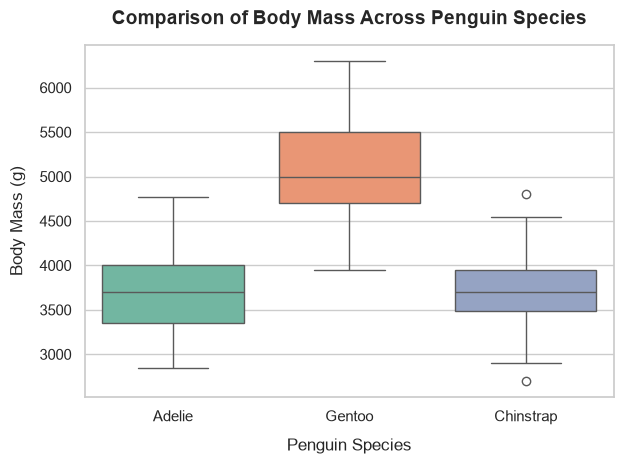

In [14]:


# Create a boxplot to compare body mass distributions across species
# We include data points using swarmplot or stripplot for added detail, or keep it clean with a boxplot
sns.boxplot(
    data=df,
    x='species',
    y='body_mass_g',
    palette='Set2',
    hue='species',
    legend=False
)

# Add informative titles and axis labels
plt.title('Comparison of Body Mass Across Penguin Species', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Penguin Species', fontsize=12, labelpad=10)
plt.ylabel('Body Mass (g)', fontsize=12, labelpad=10)

# Display the plot
plt.tight_layout()
plt.show()

Returned explanation of Steps:
Explanation of Steps:
Summarize Missing Data: Uses isnull().sum() and calculates percentages to identify which columns contain missing values (such as measurements or sex) and how many records are affected.

Compare Body Mass: Uses groupby() combined with aggregation functions (mean, median, std, etc.) to provide a statistical comparison of body_mass_g across each penguin species.

Produce Labeled Chart: Uses seaborn.boxplot() to visually compare the distribution, median, and spread of body masses for each species, complete with clear titles and axis labels.

In [15]:
#The AI code ran with no errors. Now verify.

#Step 5 verification output:
my_df.groupby("species")["body_mass_g"].mean()

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

In [16]:
df.shape

(344, 8)

The mean body mass numbers are the same and the shape is the same. I named my_df to save my dataframe so I could compare before and after AI got involved. I did not ask AI to drop the nulls, just identify them and they were not dropped.

# Step 6

Promt Log
Tool: Gemini 
Is there another way to show this data to gain more information about penguins. 

Gemini response:
Yes, there are several powerful ways to visualize and explore the Palmer penguins dataset beyond a standard boxplot to uncover deeper relationships, clusters, and distributions:

1. Pair Plot / Scatter Matrix (sns.pairplot)
What it shows: Scatter plots for every possible numeric pair of variables (bill length, bill depth, flipper length, body mass) mapped across a grid, with distributions (histograms or KDE plots) on the diagonal.

Why it’s useful: It lets you see multi-variable correlations instantly and highlights how distinctly different species cluster together across multiple physical dimensions.

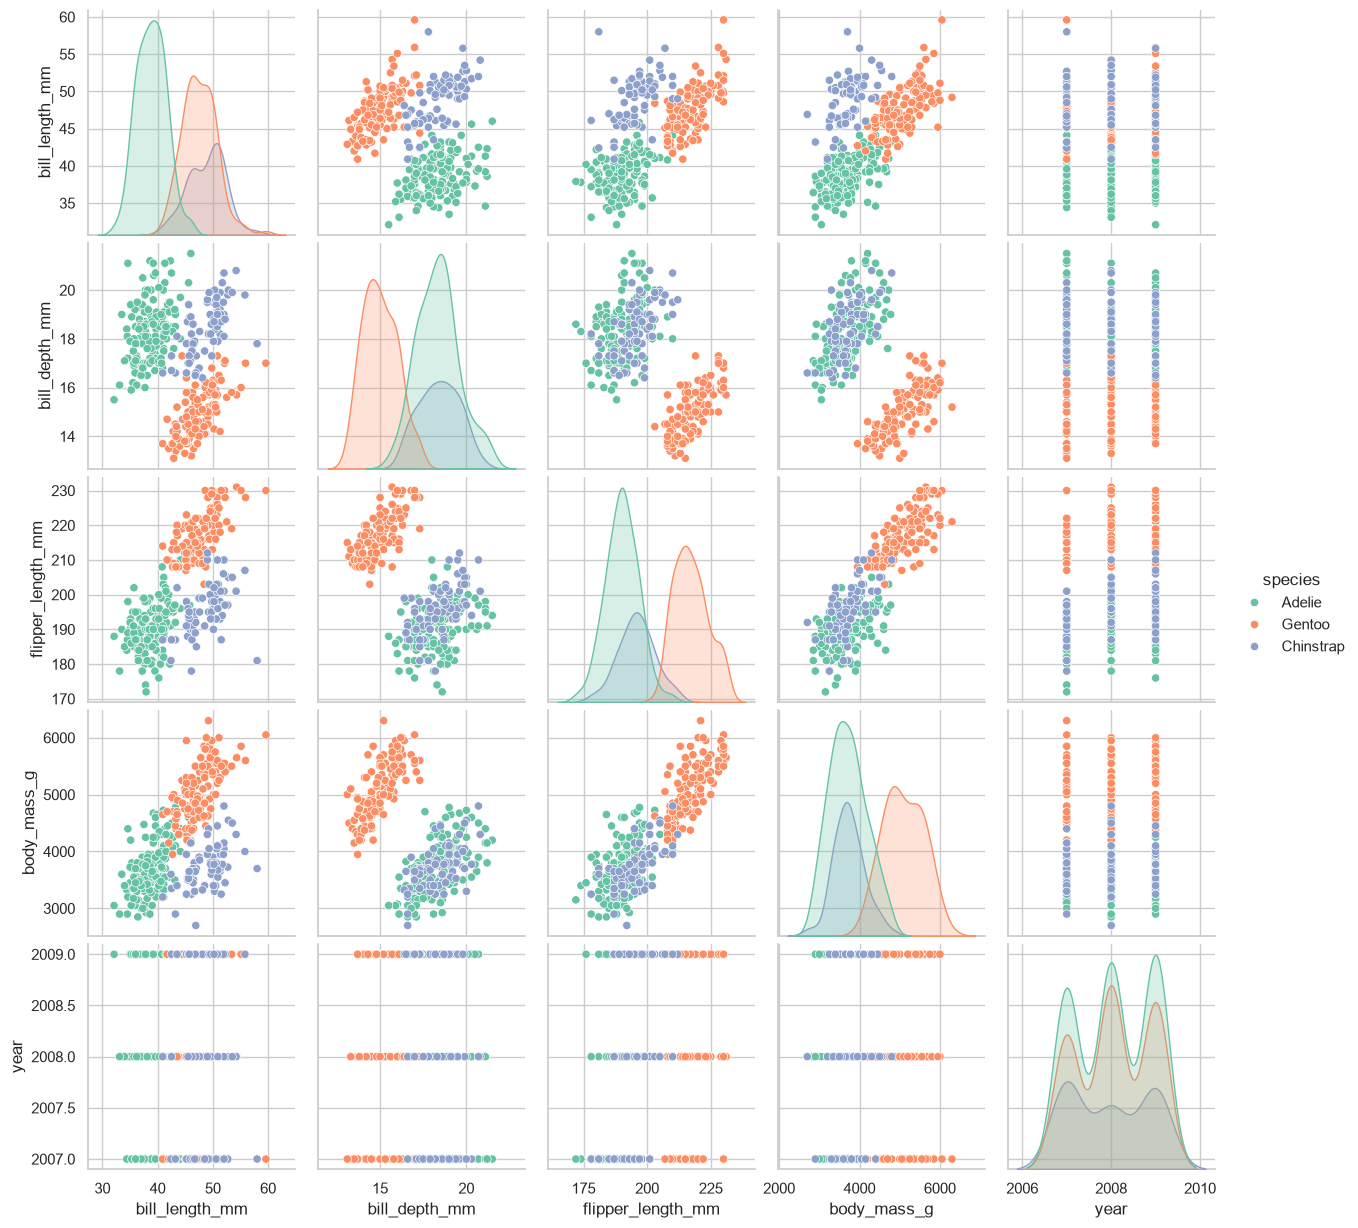

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pairplot colored by species, showing relationships across all numeric features
sns.pairplot(df.dropna(), hue='species', palette='Set2', diag_kind='kde')
plt.show()

2. Faceted Scatter Plot with Regression (sns.lmplot or sns.scatterplot)
What it shows: A scatter plot of flipper length vs. body mass (or bill dimensions), separated or colored by species and sex.

Why it’s useful: Adding regression lines helps you see if body mass scales differently with flipper length depending on the species or gender, revealing sexual dimorphism or allometric trends.

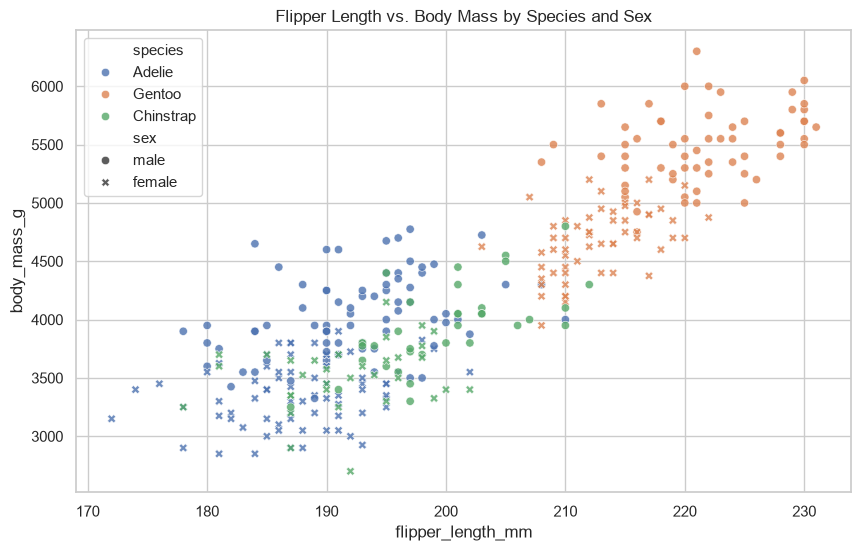

In [18]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='flipper_length_mm', 
    y='body_mass_g', 
    hue='species', 
    style='sex', 
    palette='deep',
    alpha=0.8
)
plt.title('Flipper Length vs. Body Mass by Species and Sex')
plt.show()

3. Violin Plot (sns.violinplot)
What it shows: Similar to a boxplot, but includes a rotated kernel density plot on each side to show the probability density of the data at different values.

Why it’s useful: It shows multimodal distributions (e.g., if a species has two distinct peaks in body mass or measurement ranges) that a boxplot might hide.

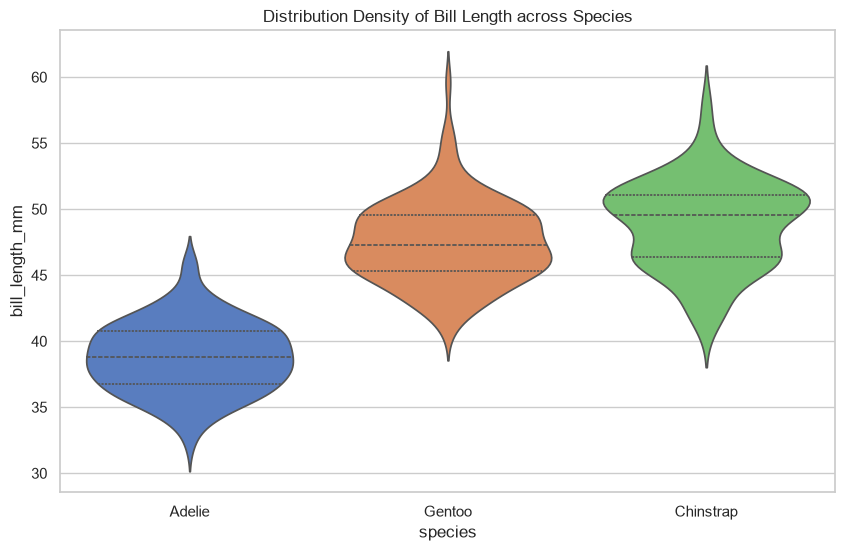

In [19]:
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x='species', y='bill_length_mm', hue='species', palette='muted', inner='quartile', legend=False)
plt.title('Distribution Density of Bill Length across Species')
plt.show()

AI had great suggestion for ways to visualize the data. I really wanted to see a simple body mass by species and sex so I asked it to create that for me. The mass of charts is interesting, the scatter of body mass and flipper by species and sex is too messy for my tired eyes right now. I love the look of the violin plot but don't want to take the time to understand it right now.

# Step 7:
I chose to do my own chart but asked how to do it:

Tool: Gemini Write Python using pandas and seaborn to: (1) compare [body_mass_g] across [species] and [sex] (2) do not include rows with no [sex] values (3) produce one labeled chart. Explain each step in comments.

In [20]:
#AI Generated Code

# ==========================================
# (1) Filter out rows with missing [sex] values
# ==========================================
# Drop any rows where the 'sex' column is NaN to ensure clean comparisons
df_filtered = df.dropna(subset=['sex']).copy()

# ==========================================
# (2) Compare [body_mass_g] across [species] and [sex]
# ==========================================
# Group by both species and sex to calculate descriptive statistics for body mass
body_mass_stats = df_filtered.groupby(['species', 'sex'])['body_mass_g'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).reset_index()

print("--- Body Mass (g) Comparison Across Species and Sex ---")
print(body_mass_stats.to_string(index=False))
print("\n")

--- Body Mass (g) Comparison Across Species and Sex ---
  species    sex  count        mean  median        std    min    max
   Adelie female     73 3368.835616  3400.0 269.380102 2850.0 3900.0
   Adelie   male     73 4043.493151  4000.0 346.811553 3325.0 4775.0
Chinstrap female     34 3527.205882  3550.0 285.333912 2700.0 4150.0
Chinstrap   male     34 3938.970588  3950.0 362.137550 3250.0 4800.0
   Gentoo female     58 4679.741379  4700.0 281.578294 3950.0 5200.0
   Gentoo   male     61 5484.836066  5500.0 313.158596 4750.0 6300.0




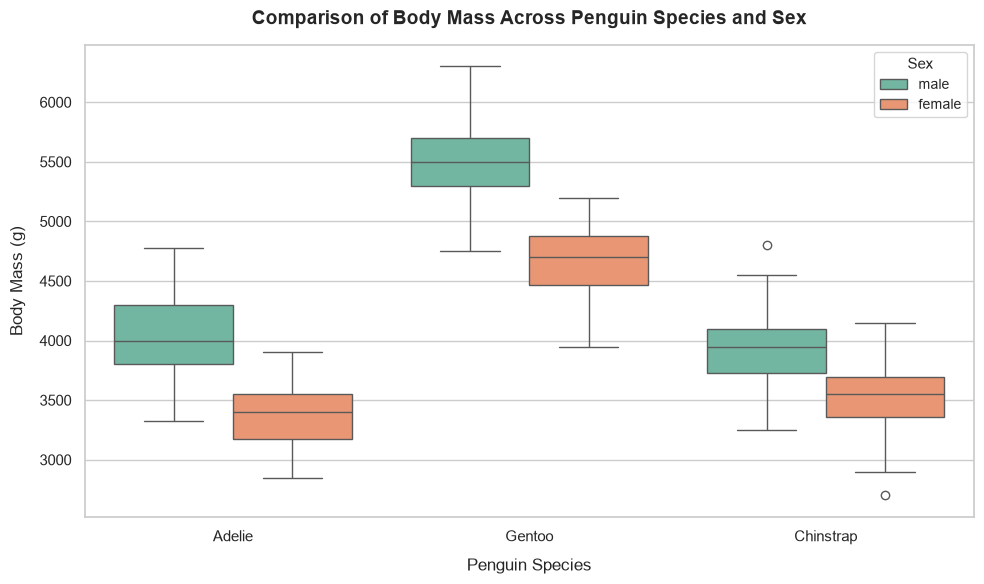

In [21]:

# ==========================================
# (3) Produce one labeled chart
# ==========================================
# Set the visual style for seaborn
sns.set_theme(style="whitegrid")

# Initialize the matplotlib figure
plt.figure(figsize=(10, 6))

# Create a grouped boxplot comparing body mass across species, split/colored by sex
sns.boxplot(
    data=df_filtered,
    x='species',
    y='body_mass_g',
    hue='sex',
    palette='Set2'
)

# Add informative titles and axis labels
plt.title('Comparison of Body Mass Across Penguin Species and Sex', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Penguin Species', fontsize=12, labelpad=10)
plt.ylabel('Body Mass (g)', fontsize=12, labelpad=10)

# Position and style the legend
plt.legend(title='Sex', title_fontsize='11', fontsize='10', loc='upper right')

# Display the plot
plt.tight_layout()
plt.show()

# Step 8
I would never paste into an AI tool a dataset that contains real names, identification numbers, weight, phone numbers, addresses etc.

https://github.com/acamend/cs82a-portfolio